# **SMART CITY MULTIMODAL MOBILITY**
#### Case File: The STN_003 "Hardware Failure"

#### **Importing Libraries**

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

#### **Import Data**

In [ ]:
city_heartbeat = pd.read_json("/content/city_heartbeat.json")
subway_turnstile = pd.read_csv("/content/subway_turnstile.csv")
scooter_rides = pd.read_csv("/content/scooter_rides.csv")

pd.set_option('display.max_rows', None)

In [ ]:
city_heartbeat.head(5)

,2026-01-06,2026-02-06,2026-06-03,2026-06-04,2026-05-06,2026-06-06,2026-07-06,2026-06-08,2026-06-09,2026-10-06,...,2026-06-21,2026-06-22,2026-06-23,2026-06-24,2026-06-25,2026-06-26,2026-06-27,2026-06-28,2026-06-29,2026-06-30
day_number,1,2,3,4,5,6,7,8,9,10,...,21,22,23,24,25,26,27,28,29,30
weather,"{'temperature_c': 27.2, 'humidity_pct': 56.2, ...","{'temperature_c': 19.7, 'humidity_pct': 45.2, ...","{'temperature_c': 25.5, 'humidity_pct': 82.5, ...","{'temperature_c': 19.4, 'humidity_pct': 43.0, ...","{'temperature_c': 18.6, 'humidity_pct': 57.4, ...","{'temperature_c': 30.2, 'humidity_pct': 82.4, ...","{'temperature_c': 22.1, 'humidity_pct': 76.3, ...","{'temperature_c': 24.7, 'humidity_pct': 42.9, ...","{'temperature_c': 18.0, 'humidity_pct': 55.7, ...","{'temperature_c': 26.6, 'humidity_pct': 80.9, ...",...,"{'temperature_c': 20.7, 'humidity_pct': 61.0, ...","{'temperature_c': 28.4, 'humidity_pct': 74.2, ...","{'temperature_c': 22.6, 'humidity_pct': 49.7, ...","{'temperature_c': 23.9, 'humidity_pct': 77.0, ...","{'temperature_c': 30.4, 'humidity_pct': 80.6, ...","{'temperature_c': 23.0, 'humidity_pct': 84.6, ...","{'temperature_c': 30.9, 'humidity_pct': 57.4, ...","{'temperature_c': 23.0, 'humidity_pct': 83.5, ...","{'temperature_c': 27.9, 'humidity_pct': 46.5, ...","{'temperature_c': 29.2, 'humidity_pct': 58.6, ..."
civic_pulse,"{'traffic_congestion_index': 0.56, 'reported_i...","{'traffic_congestion_index': 0.76, 'reported_i...","{'traffic_congestion_index': 0.34, 'reported_i...",{'traffic_congestion_index': 0.600000000000000...,"{'traffic_congestion_index': 0.46, 'reported_i...","{'traffic_congestion_index': 0.65, 'reported_i...","{'traffic_congestion_index': 0.62, 'reported_i...","{'traffic_congestion_index': 0.97, 'reported_i...",{'traffic_congestion_index': 0.820000000000000...,"{'traffic_congestion_index': 0.68, 'reported_i...",...,{'traffic_congestion_index': 0.690000000000000...,"{'traffic_congestion_index': 0.79, 'reported_i...","{'traffic_congestion_index': 0.4, 'reported_in...","{'traffic_congestion_index': 0.8, 'reported_in...","{'traffic_congestion_index': 0.56, 'reported_i...","{'traffic_congestion_index': 0.74, 'reported_i...","{'traffic_congestion_index': 0.37, 'reported_i...","{'traffic_congestion_index': 0.87, 'reported_i...","{'traffic_congestion_index': 0.44, 'reported_i...","{'traffic_congestion_index': 0.75, 'reported_i..."


In [ ]:
subway_turnstile.head(5)

,station_id,timestamp,entries,exits
0,Stn_009,2026-06-21 02:00:00,73,68
1,Stn_010,2026-06-01 17:00:00,433,396
2,STN_009,2026-06-06 21:00:00,137,110
3,STN_001,2026-06-26 04:00:00,92,92
4,stn_009,2026-06-26 13:00:00,85,69


In [ ]:
scooter_rides.head(5)

,ride_id,scooter_id,user_id,start_time,end_time,start_lat,start_lng,end_lat,end_lng,battery_level,user_rating
0,RIDE_000000,SCOOT_0048,USER_00448,2026-06-21T04:03:12,1782014832,40.7405° N,-73.9380,40.742477,-73.933396,55,NaN
1,RIDE_000001,SCOOT_0358,USER_00866,2026-06-08T18:23:57,06/08/2026 07:04 PM,40.711863,-74.006937,40.716601,-74.004634,1%,2
2,RIDE_000002,SCOOT_0275,USER_00256,1781172421,2026-06-11T10:19:01,40.710922,-74.00383,40.709532,-74.005227,34,4
3,RIDE_000003,SCOOT_0120,USER_00207,1782827215,06/30/2026 01:54 PM,40.705339,-74.026266,40.700164,-74.027952,99%,1
4,RIDE_000004,SCOOT_0274,USER_01494,2026-06-13T10:07:14,06/13/2026 10:39 AM,40.7411° N,73.9713° W,40.738419,-73.975552,10%,2


### **Phase 1 — Cleaning & Standardization ("The Grunt Work")**

**1.1 String Operations**

In [ ]:
# Clearing Station ID's Inconsistencies
subway_turnstile['station_id'].unique()

array(['Stn_009', 'Stn_010', 'STN_009', 'STN_001 ', 'stn_009',
       'STN_009  ', 'STN_008  ', 'STN_006  ', 'stn_002', 'STN_007  ',
       'STN_010  ', 'STN_002', 'STN_003 ', ' stn_003', 'STN_010 ',
       'STN_005  ', 'STN_007 ', 'Stn_008', 'stn_008', 'STN_004 ',
       'Stn_001', 'Stn_005', 'Stn_002', 'STN_002  ', ' stn_009',
       ' stn_006', 'stn_010', ' stn_007', 'STN_001', ' stn_001',
       'STN_007', 'STN_004  ', ' stn_002', 'STN_008', ' stn_004',
       'STN_005', 'STN_009 ', 'stn_006', 'stn_005', 'STN_010', 'STN_006',
       'Stn_006', 'stn_007', 'stn_001', 'Stn_007', 'Stn_004', 'Stn_003',
       'STN_003', 'stn_003', 'STN_006 ', ' stn_010', 'STN_005 ',
       'STN_008 ', ' stn_008', ' stn_005', 'STN_002 ', 'STN_003  ',
       'STN_001  ', 'stn_004', 'STN_004'], dtype=object)

In [ ]:
subway_turnstile['station_id'] = subway_turnstile['station_id'].str.strip().str.lower()
subway_turnstile['station_id'].unique()

array(['stn_009', 'stn_010', 'stn_001', 'stn_008', 'stn_006', 'stn_002',
       'stn_007', 'stn_003', 'stn_005', 'stn_004'], dtype=object)

In [ ]:
print("Number of Station IDs after data cleaning:", subway_turnstile['station_id'].nunique())

Number of Station IDs after data cleaning: 10


In [ ]:
# Clearning Start Lat's Inconsistencies
scooter_rides['start_lat'].unique()

array(['40.7405° N', '40.711863', '40.710922', ..., '40.7321° N',
       '40.720946', '40.718309'], dtype=object)

In [ ]:
# I am applying operations on two rows. So, I'll use lambda
scooter_rides[['start_lat','start_lng']] = scooter_rides[['start_lat','start_lng']].apply(lambda x: x.str.replace("°","")\
                                                                                         .str.replace("N","")\
                                                                                         .str.replace("W","").str.replace("%","")\
                                                                                         .str.strip() )

In [ ]:
print("Start Lat Unique: ",scooter_rides['start_lat'].unique(),"\n\n",
      "Start Lng Unique: ", scooter_rides['start_lng'].unique())

Start Lat Unique:  ['40.7405' '40.711863' '40.710922' ... '40.7321' '40.720946' '40.718309'] 

 Start Lng Unique:  ['-73.9380' '-74.006937' '-74.00383' ... '-74.009677' '-74.007651'
 '-74.004487']


**1.2 Type Casting**

In [ ]:
#Data Type before converting to Float
print("Start Lat Data Type: ", scooter_rides['start_lat'].dtype,"\n\n",
      "Start Lng Data Type: ", scooter_rides['start_lng'].dtype, )

Start Lat Data Type:  object 

 Start Lng Data Type:  object


In [ ]:
#Data Type after converting to Float
scooter_rides[['start_lat', 'start_lng']] = scooter_rides[['start_lat', 'start_lng']].astype(float)
print("Start Lat Data Type: ", scooter_rides['start_lat'].dtype,"\n\n",
      "Start Lng Data Type: ", scooter_rides['start_lng'].dtype, )

Start Lat Data Type:  float64 

 Start Lng Data Type:  float64


In [ ]:
# Removing Whitespaces and %
scooter_rides['battery_level'] = scooter_rides['battery_level'].str.replace("%","")

#Casting to numeric type
# errors='coerce' argument tells pandas how to handle values that cannot be converted into a number
scooter_rides['battery_level'] = pd.to_numeric(scooter_rides['battery_level'], errors='coerce')
print("Battery Life Data Type: ", scooter_rides['battery_level'].dtype)
#In pandas NaN is considered a floating-point number. Hence the datatype is showing as float64

Battery Life Data Type:  float64


In [ ]:
# For consistency and uniformity, text is replaced with character strings and then the whole column is converted to numeric
print("Unique values before manipulations: ",scooter_rides['user_rating'].unique())
scooter_rides['user_rating'] = scooter_rides['user_rating'].str.replace('five star', '5').replace('three', '3')
scooter_rides['user_rating'] = pd.to_numeric(scooter_rides['user_rating'], errors='coerce')
print("Unique values after manipulations: ",scooter_rides['user_rating'].unique())

Unique values before manipulations:  [nan '2' '4' '1' '3' '5' '1.0' 'five star' 'three' '2.0']
Unique values after manipulations:  [nan  2.  4.  1.  3.  5.]


In [ ]:
def is_number(val):
  try:
    float(val) #if it's float then convert the datetime given in seconds to datetime
    return pd.to_datetime(val, unit="s")
  except ValueError:
    return pd.to_datetime(val, format='mixed', dayfirst=True, errors='coerce')

In [ ]:
# Start Time and End Time in Scooter Rides contains a mix of ISO 8601 strings, US-style strings and raw Unix epoch integers in seconds.
# Converting to a standard date/time format.

scooter_rides['start_time'] = scooter_rides['start_time'].apply(lambda x: is_number(x))
scooter_rides['end_time'] = scooter_rides['end_time'].apply(lambda x: is_number(x))
print("Data Type of Start Time: ", scooter_rides['start_time'].dtype, "\n\n",
      "Data Type of End Time: ", scooter_rides['end_time'].dtype, "\n\n")

/tmp/ipykernel_1065/2058963002.py:4: FutureWarning: The behavior of 'to_datetime' with 'unit' when parsing strings is deprecated. In a future version, strings will be parsed as datetime strings, matching the behavior without a 'unit'. To retain the old behavior, explicitly cast ints or floats to numeric type before calling to_datetime.
  return pd.to_datetime(val, unit="s")


Data Type of Start Time:  datetime64[ns] 

 Data Type of End Time:  datetime64[ns] 




In [ ]:
scooter_rides.dtypes

,0
ride_id,object
scooter_id,object
user_id,object
start_time,datetime64[ns]
end_time,datetime64[ns]
start_lat,float64
start_lng,float64
end_lat,float64
end_lng,float64
battery_level,float64


In [ ]:
# Converting Subway Turnstile’s Entries and Exits to numeric to account for ‘Device Error’ values.
subway_turnstile[['entries', 'exits']] = subway_turnstile[['entries', 'exits']].apply(pd.to_numeric, errors='coerce')
print("Subway Turnstile Entries Data Type: ", subway_turnstile['entries'].dtype, "\n\n",
      "Subway Turnstile Exits Data Type: ", subway_turnstile['exits'].dtype)

Subway Turnstile Entries Data Type:  float64 

 Subway Turnstile Exits Data Type:  float64


In [ ]:
subway_turnstile['timestamp'] = pd.to_datetime(subway_turnstile['timestamp'])

In [ ]:
subway_turnstile.dtypes

,0
station_id,object
timestamp,datetime64[ns]
entries,float64
exits,float64


**1.3 Handling Anomalies**

In [ ]:
# To check if the negative values cluster around a particular station, day, or hour
subway_turnstile["negative_entries"] = (subway_turnstile["entries"] < 0).astype(int) #if negative entries then that is conversted to int
subway_turnstile["negative_exits"] = (subway_turnstile["exits"] < 0).astype(int)
subway_turnstile["date"] = subway_turnstile["timestamp"].dt.date
subway_turnstile["hour"] = subway_turnstile["timestamp"].dt.hour

**1.3.1 Visualizing negative entries OR exits**

In [ ]:
subway_turnstile[(subway_turnstile['entries']<0) | (subway_turnstile['exits']<0)]

,station_id,timestamp,entries,exits,negative_entries,negative_exits,date,hour
6,stn_008,2026-06-08 11:00:00,105.0,-90.0,0,1,2026-06-08,11
18,stn_007,2026-06-15 00:00:00,80.0,-82.0,0,1,2026-06-15,0
29,stn_002,2026-06-25 17:00:00,-383.0,387.0,1,0,2026-06-25,17
36,stn_009,2026-06-15 08:00:00,-432.0,431.0,1,0,2026-06-15,8
39,stn_002,2026-06-02 18:00:00,-482.0,408.0,1,0,2026-06-02,18
44,stn_001,2026-06-21 00:00:00,78.0,-66.0,0,1,2026-06-21,0
79,stn_010,2026-06-12 06:00:00,253.0,-263.0,0,1,2026-06-12,6
85,stn_002,2026-06-11 18:00:00,NaN,-386.0,0,1,2026-06-11,18
104,stn_002,2026-06-15 17:00:00,455.0,-441.0,0,1,2026-06-15,17
110,stn_010,2026-06-15 22:00:00,-81.0,77.0,1,0,2026-06-15,22


**1.3.2 Percentage of Overall Negative Entries & Exits**

In [ ]:
percentage_of_negative_entries = round(((subway_turnstile['entries']<0).mean())*100, 2)
print("Percentage of Negative Entries: ", percentage_of_negative_entries, "%")

percentage_of_negative_exits = round(((subway_turnstile['exits']<0).mean())*100, 2)
print("Percentage of Negative Exits: ", percentage_of_negative_exits, "%")

Percentage of Negative Entries:  3.54 %
Percentage of Negative Exits:  4.95 %


**1.3.3 Percentage of Negative Entries and Exits Per Station**

In [ ]:
negative_ratios_entries = subway_turnstile.groupby("station_id")["entries"].apply(lambda x: (x < 0).mean())

negative_ratios_exits = subway_turnstile.groupby("station_id")["exits"].apply(lambda x: (x < 0).mean())

stations = pd.concat([negative_ratios_entries, negative_ratios_exits],axis=1,keys=["-ve Entries %", "-ve Exits %"],)

print("\nNegative Ratios of Exits Per Station")
print(stations)


Negative Ratios of Exits Per Station
            -ve Entries %  -ve Exits %
station_id                            
stn_001          0.030303     0.050505
stn_002          0.020202     0.045455
stn_003          0.055556     0.045455
stn_004          0.025253     0.040404
stn_005          0.045455     0.060606
stn_006          0.015152     0.055556
stn_007          0.025253     0.045455
stn_008          0.045455     0.055556
stn_009          0.040404     0.060606
stn_010          0.050505     0.035354


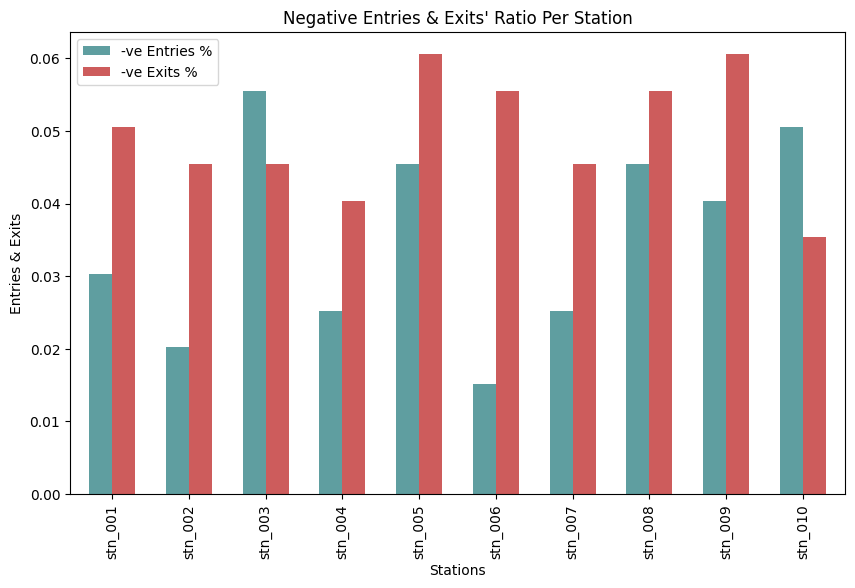

In [ ]:
stations.plot(kind="bar", figsize=(10, 6), width=0.6, color=["#5F9EA0", "#CD5C5C"])
plt.title("Negative Entries & Exits' Ratio Per Station")
plt.xlabel("Stations")
plt.ylabel("Entries & Exits")
plt.show()

**1.3.4 Percentage of Negative Entries and Exits Per Hour**

In [ ]:
hour_negative_entries = subway_turnstile.groupby('hour')['negative_entries'].mean() * 100

hour_negative_exits = subway_turnstile.groupby('hour')['negative_exits'].mean() * 100

hours = pd.concat([hour_negative_entries, hour_negative_exits],axis=1,keys=["-ve Entries %", "-ve Exits %"])

print("\nNegative Ratios of Exits Per Hour")
print(hours)


Negative Ratios of Exits Per Hour
      -ve Entries %  -ve Exits %
hour                            
0          1.063830     4.255319
1          3.370787     3.370787
2          1.250000     5.000000
3          4.878049     4.878049
4          1.282051     3.846154
5          3.846154    10.256410
6          7.692308     7.692308
7          4.705882     8.235294
8          4.597701     5.747126
9          5.747126     3.448276
10         1.250000     6.250000
11         1.351351     5.405405
12         4.651163     5.813953
13         4.494382     3.370787
14         3.703704     4.938272
15         3.333333     4.444444
16         3.846154     2.564103
17         4.761905     4.761905
18         2.409639     8.433735
19         7.792208     0.000000
20         4.109589     4.109589
21         1.176471     5.882353
22         1.111111     4.444444
23         3.529412     2.352941


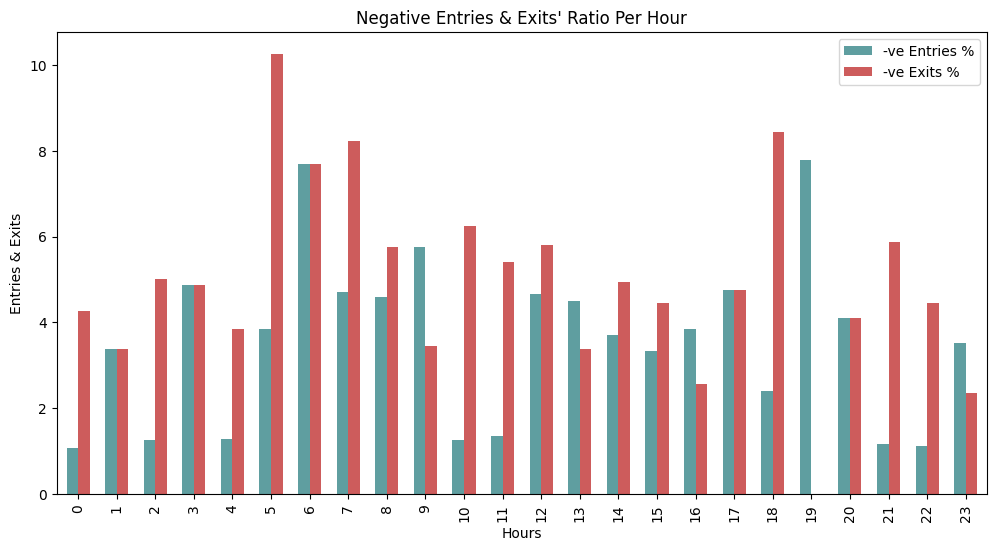

In [ ]:
hours.plot(kind="bar", figsize=(12, 6), width=0.6, color=["#5F9EA0", "#CD5C5C"])
plt.title("Negative Entries & Exits' Ratio Per Hour")
plt.xlabel("Hours")
plt.ylabel("Entries & Exits")
plt.show()

**1.3.5 Percentage of Negative Entries and Exits Per Day**

In [ ]:
date_negative_entries = subway_turnstile.groupby('date')['negative_entries'].mean() * 100

date_negative_exits = subway_turnstile.groupby('date')['negative_exits'].mean() * 100

date = pd.concat([date_negative_entries, date_negative_exits],axis=1,keys=["-ve Entries %", "-ve Exits %"],)

print("\nNegative Ratios of Entries & Exits Per Day")
print(date)


Negative Ratios of Entries & Exits Per Day
            -ve Entries %  -ve Exits %
date                                  
2026-06-01       3.333333     3.333333
2026-06-02       8.333333     6.666667
2026-06-03       0.000000     1.666667
2026-06-04       3.333333     6.666667
2026-06-05       5.000000     3.333333
2026-06-06       1.666667     8.333333
2026-06-07       6.666667     6.666667
2026-06-08       1.666667     8.333333
2026-06-09       5.000000     1.666667
2026-06-10       5.000000     1.666667
2026-06-11       1.666667    10.000000
2026-06-12       5.000000     5.000000
2026-06-13       1.666667     5.000000
2026-06-14       1.666667     0.000000
2026-06-15       2.083333     5.000000
2026-06-16       1.666667     3.333333
2026-06-17       3.333333     8.333333
2026-06-18       0.000000     1.666667
2026-06-19       3.333333     5.000000
2026-06-20      10.000000     1.666667
2026-06-21       1.666667     1.666667
2026-06-22       3.333333     8.333333
2026-06-23       0.0

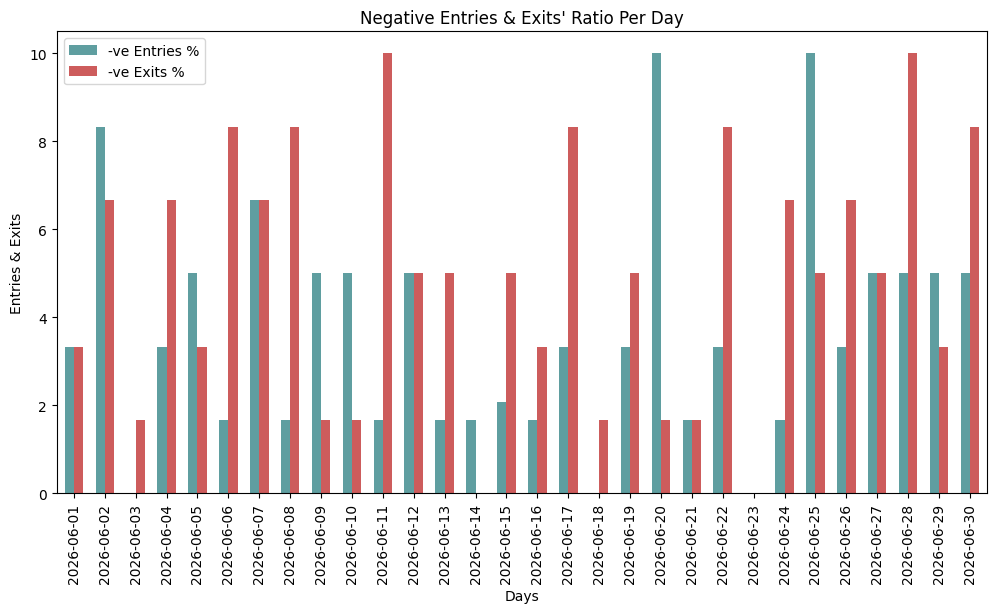

In [ ]:
date.plot(kind="bar", figsize=(12, 6), width=0.6, color=["#5F9EA0", "#CD5C5C"])
plt.title("Negative Entries & Exits' Ratio Per Day")
plt.xlabel("Days")
plt.ylabel("Entries & Exits")
plt.show()

**1.3.6 Percentage of Negative Entries and Exits Per Day at each Station**

In [ ]:
#  ENTRIES
# Although pivot table for percentage of negative entries and exits per day at each station weren't needed.
# However, this pivot tables presents a summary of the three data columns in a cummulative form.

pivot_subway_entries_per_day = subway_turnstile.pivot_table(
    index="date", columns="station_id", values="negative_entries"
)
#index: y axis, columns: column values, values: data to be filled according to

pivot_subway_entries_per_day

station_id,stn_001,stn_002,stn_003,stn_004,stn_005,stn_006,stn_007,stn_008,stn_009,stn_010
date,,,,,,,,,,
2026-06-01,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.166667,0.000000,0.000000,0.166667
2026-06-02,0.000000,0.166667,0.166667,0.000000,0.166667,0.000000,0.166667,0.000000,0.000000,0.166667
2026-06-03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2026-06-04,0.333333,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2026-06-05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.166667,0.333333,0.000000,0.000000
2026-06-06,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.166667,0.000000
2026-06-07,0.000000,0.000000,0.166667,0.000000,0.000000,0.000000,0.000000,0.166667,0.166667,0.166667
2026-06-08,0.000000,0.000000,0.000000,0.000000,0.166667,0.000000,0.000000,0.000000,0.000000,0.000000
2026-06-09,0.000000,0.000000,0.166667,0.000000,0.000000,0.166667,0.000000,0.000000,0.166667,0.000000


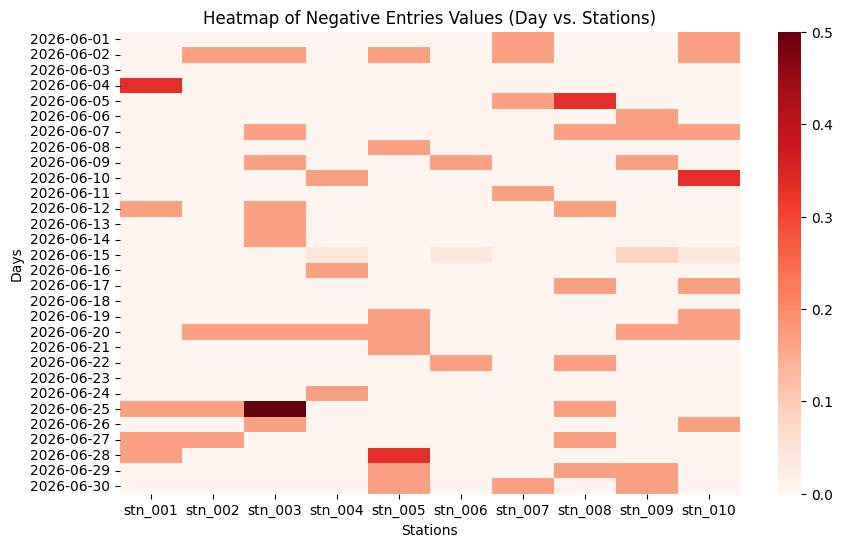

In [ ]:
# This heatmap presents a clear picture of the fact that negative values were completely random
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_subway_entries_per_day, cmap="Reds", cbar=True, yticklabels=1)

plt.title("Heatmap of Negative Entries Values (Day vs. Stations)")
plt.xlabel("Stations")
plt.ylabel("Days")
plt.show()

In [ ]:
#  EXITS
pivot_subway_exits_per_day = subway_turnstile.pivot_table(
    index="date", columns="station_id", values="negative_exits"
)
#index: y axis, columns: column values, values: data to be filled according to

pivot_subway_exits_per_day

station_id,stn_001,stn_002,stn_003,stn_004,stn_005,stn_006,stn_007,stn_008,stn_009,stn_010
date,,,,,,,,,,
2026-06-01,0.000000,0.166667,0.166667,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2026-06-02,0.333333,0.000000,0.000000,0.000000,0.166667,0.166667,0.000000,0.000000,0.000000,0.000000
2026-06-03,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.166667,0.000000,0.000000
2026-06-04,0.166667,0.000000,0.000000,0.166667,0.000000,0.000000,0.333333,0.000000,0.000000,0.000000
2026-06-05,0.000000,0.000000,0.000000,0.000000,0.166667,0.000000,0.166667,0.000000,0.000000,0.000000
2026-06-06,0.000000,0.000000,0.333333,0.166667,0.000000,0.000000,0.000000,0.166667,0.166667,0.000000
2026-06-07,0.000000,0.000000,0.000000,0.166667,0.166667,0.000000,0.166667,0.166667,0.000000,0.000000
2026-06-08,0.000000,0.166667,0.000000,0.000000,0.000000,0.333333,0.000000,0.166667,0.000000,0.166667
2026-06-09,0.000000,0.000000,0.000000,0.000000,0.166667,0.000000,0.000000,0.000000,0.000000,0.000000


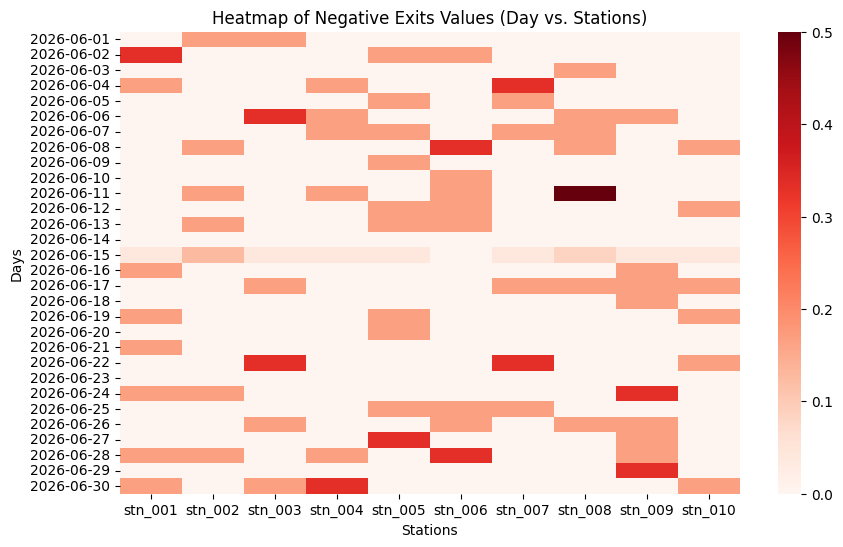

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_subway_exits_per_day, cmap="Reds", cbar=True, yticklabels=1)

plt.title("Heatmap of Negative Exits Values (Day vs. Stations)")
plt.xlabel("Stations")
plt.ylabel("Days")
plt.show()

**1.3.7 Percentage of Negative Entries and Exits Per Hour at each Station**

In [ ]:
#  ENTRIES
pivot_subway_entries_per_hour = subway_turnstile.pivot_table(
    index="hour", columns="station_id", values="negative_entries"
)
#index: y axis, columns: column values, values: data to be filled according to

pivot_subway_entries_per_hour

station_id,stn_001,stn_002,stn_003,stn_004,stn_005,stn_006,stn_007,stn_008,stn_009,stn_010
hour,,,,,,,,,,
0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.125000,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.200000,0.090909,0.000000,0.090909,0.000000
2,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.076923
3,0.000000,0.000000,0.000000,0.000000,0.125000,0.166667,0.000000,0.000000,0.000000,0.250000
4,0.000000,0.000000,0.000000,0.000000,0.125000,0.000000,0.000000,0.000000,0.000000,0.000000
5,0.000000,0.000000,0.125000,0.000000,0.000000,0.000000,0.000000,0.181818,0.000000,0.000000
6,0.166667,0.000000,0.142857,0.000000,0.200000,0.000000,0.000000,0.285714,0.000000,0.000000
7,0.090909,0.000000,0.090909,0.000000,0.000000,0.000000,0.100000,0.000000,0.111111,0.000000
8,0.000000,0.000000,0.100000,0.000000,0.000000,0.000000,0.000000,0.076923,0.222222,0.000000


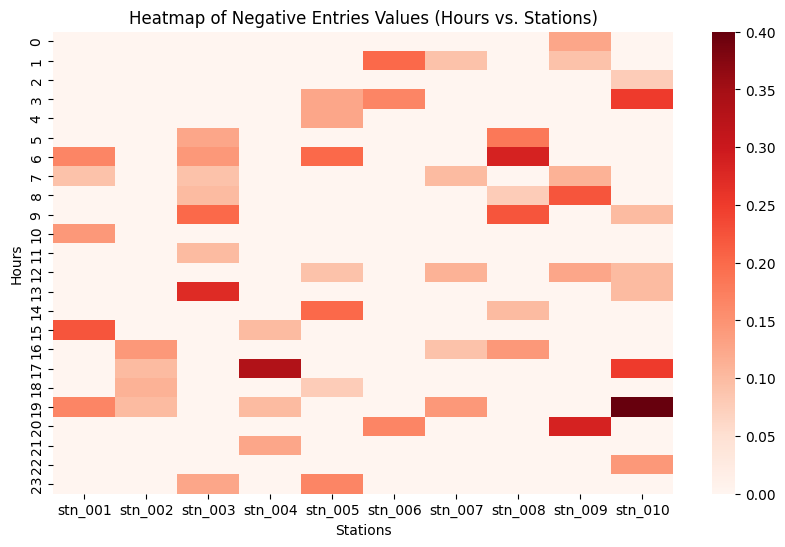

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_subway_entries_per_hour, cmap="Reds", cbar=True, yticklabels=1)

plt.title("Heatmap of Negative Entries Values (Hours vs. Stations)")
plt.xlabel("Stations")
plt.ylabel("Hours")
plt.show()

In [ ]:
#  EXITS
pivot_subway_exits_per_hour = subway_turnstile.pivot_table(
    index="hour", columns="station_id", values="negative_exits"
)
#index: y axis, columns: column values, values: data to be filled according to

pivot_subway_exits_per_hour

station_id,stn_001,stn_002,stn_003,stn_004,stn_005,stn_006,stn_007,stn_008,stn_009,stn_010
hour,,,,,,,,,,
0,0.100000,0.000000,0.083333,0.090909,0.000000,0.000000,0.166667,0.000000,0.000000,0.000000
1,0.000000,0.000000,0.000000,0.000000,0.000000,0.200000,0.000000,0.111111,0.090909,0.000000
2,0.111111,0.000000,0.166667,0.111111,0.200000,0.000000,0.000000,0.000000,0.000000,0.000000
3,0.000000,0.000000,0.200000,0.000000,0.125000,0.000000,0.222222,0.000000,0.000000,0.000000
4,0.000000,0.125000,0.000000,0.100000,0.000000,0.166667,0.000000,0.000000,0.000000,0.000000
5,0.250000,0.125000,0.000000,0.000000,0.000000,0.142857,0.000000,0.181818,0.250000,0.100000
6,0.000000,0.000000,0.000000,0.142857,0.000000,0.000000,0.125000,0.000000,0.200000,0.666667
7,0.363636,0.000000,0.090909,0.100000,0.000000,0.000000,0.100000,0.000000,0.000000,0.000000
8,0.000000,0.250000,0.100000,0.000000,0.111111,0.000000,0.000000,0.153846,0.000000,0.000000


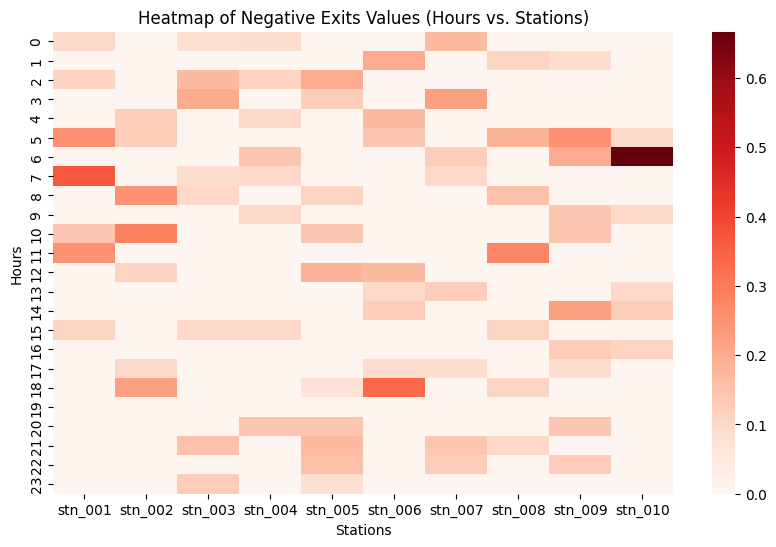

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_subway_exits_per_hour, cmap="Reds", cbar=True, yticklabels=1)

plt.title("Heatmap of Negative Exits Values (Hours vs. Stations)")
plt.xlabel("Stations")
plt.ylabel("Hours")
plt.show()

**1.3.8 Handling Negative Values**

In [ ]:
# Taking Absolute of the negative values as the above analysis show that the noise is random
subway_turnstile["entries"] = subway_turnstile["entries"].abs()
subway_turnstile["exits"] = subway_turnstile["exits"].abs()
print("Number of negative Entries:", (subway_turnstile["entries"]<0).sum(), "\n",
      "Number of negative Exits:", (subway_turnstile["exits"]<0).sum(), "\n")

#Taking mean of entries per hour for each station
mean_entries = subway_turnstile.groupby(["station_id", "hour"])["entries"].transform("mean")
mean_exits = subway_turnstile.groupby(["station_id", "hour"])["exits"].transform("mean")

#Filling NULL Values
subway_turnstile["entries"] = subway_turnstile["entries"].fillna(mean_entries)
subway_turnstile["exits"] = subway_turnstile["exits"].fillna(mean_exits)

print("Number of NULL Entries:", subway_turnstile["entries"].isnull().sum(), "\n",
      "Number of NULL Exits:", subway_turnstile["exits"].isnull().sum(), "\n")

Number of negative Entries: 0 
 Number of negative Exits: 0 

Number of NULL Entries: 0 
 Number of NULL Exits: 0 



### **Phase 2 — Aggregation & Group By ("Finding the Signal")**

**2.1 Daily total entries/exits per station**

In [ ]:
per_station_daily_entries = subway_turnstile.groupby(["station_id", "date"])["entries"].sum().reset_index()
per_station_daily_entries.pivot(index="date", columns="station_id", values="entries")

station_id,stn_001,stn_002,stn_003,stn_004,stn_005,stn_006,stn_007,stn_008,stn_009,stn_010
date,,,,,,,,,,
2026-06-01,829.000000,934.689286,1546.166667,1659.875000,1443.000000,735.0,1350.571429,1549.000000,1436.000000,1341.000000
2026-06-02,1549.000000,1189.000000,959.000000,1367.000000,822.000000,1097.0,1599.000000,1372.000000,1027.000000,1552.000000
2026-06-03,1358.000000,716.000000,1411.000000,940.000000,1447.454545,1495.0,1309.000000,1293.000000,1164.000000,1388.571429
2026-06-04,1933.800000,1242.900000,1157.000000,1343.000000,848.000000,1552.0,1348.000000,1378.000000,981.000000,599.000000
2026-06-05,1535.000000,1021.000000,1485.000000,619.000000,999.000000,895.0,1420.000000,1595.000000,1325.875000,1230.000000
2026-06-06,1441.000000,983.000000,1478.000000,1583.000000,1160.000000,1039.0,929.714286,1349.750000,1140.000000,719.875000
2026-06-07,674.000000,1210.000000,803.000000,1315.000000,1271.000000,1683.0,1169.000000,1512.000000,1675.000000,1008.291667
2026-06-08,877.000000,1885.000000,1121.666667,1247.857143,1433.250000,1831.0,901.000000,1110.000000,550.714286,1525.875000
2026-06-09,951.000000,1288.333333,1183.000000,670.966667,1777.000000,1200.0,895.000000,1860.000000,1333.000000,1732.857143


In [ ]:
per_station_daily_exits = subway_turnstile.groupby(["station_id", "date"])["exits"].sum().reset_index()
per_station_daily_exits.pivot(index="date", columns="station_id", values="exits")

station_id,stn_001,stn_002,stn_003,stn_004,stn_005,stn_006,stn_007,stn_008,stn_009,stn_010
date,,,,,,,,,,
2026-06-01,796.175000,893.000000,1558.000000,1508.0,1204.000000,653.000000,1217.333333,1436.000,1323.000000,1243.000000
2026-06-02,1412.000000,1080.000000,879.000000,1255.0,768.000000,956.000000,1452.500000,1323.000,905.166667,1482.600000
2026-06-03,1200.000000,705.000000,1259.000000,906.0,1311.000000,1329.000000,1186.000000,1158.000,1110.400000,1268.000000
2026-06-04,1700.285714,1090.000000,1046.000000,1180.0,789.000000,1457.000000,1237.000000,1268.000,896.000000,533.000000
2026-06-05,1294.000000,972.000000,1358.000000,590.0,915.000000,815.000000,1364.000000,1577.000,1260.000000,1223.000000
2026-06-06,1463.000000,885.000000,1354.000000,1473.0,1030.000000,988.000000,842.000000,1365.000,1030.000000,700.000000
2026-06-07,613.000000,1096.000000,733.000000,1125.0,1149.000000,1498.000000,1059.000000,1359.000,1573.000000,923.000000
2026-06-08,833.000000,1788.000000,1066.571429,1183.0,1297.000000,1709.800000,842.285714,1058.500,511.000000,1395.000000
2026-06-09,852.000000,1121.000000,1061.800000,634.0,1628.000000,1109.000000,774.000000,1752.000,1225.000000,1696.000000


**2.2 Average hourly turnstile flow per station**

In [ ]:
#ENTRIES
per_station_hourly_entries = subway_turnstile.groupby(["station_id", "hour"])["entries"].mean().reset_index()
per_station_hourly_entries.pivot(index="hour", columns="station_id", values="entries")

station_id,stn_001,stn_002,stn_003,stn_004,stn_005,stn_006,stn_007,stn_008,stn_009,stn_010
hour,,,,,,,,,,
0,81.600000,76.615385,77.750000,80.272727,82.000000,83.857143,80.666667,76.333333,79.714286,78.333333
1,78.750000,81.333333,77.666667,83.375000,79.000000,85.400000,81.090909,82.333333,83.909091,80.142857
2,78.250000,78.600000,81.500000,79.250000,82.200000,80.500000,76.500000,76.750000,83.500000,81.750000
3,82.083333,82.900000,77.400000,73.800000,77.750000,76.000000,80.000000,79.250000,79.375000,76.875000
4,86.400000,87.875000,90.818182,89.777778,84.625000,87.833333,89.800000,87.250000,88.923077,85.250000
5,119.000000,128.375000,123.000000,120.250000,110.000000,121.571429,123.714286,120.454545,117.000000,114.875000
6,224.000000,238.285714,220.428571,228.166667,217.800000,239.000000,225.428571,228.714286,211.200000,227.000000
7,388.909091,391.500000,401.909091,395.875000,385.000000,408.428571,405.900000,393.000000,405.000000,393.857143
8,497.375000,489.500000,464.000000,493.222222,502.250000,485.000000,463.300000,478.750000,484.666667,489.857143


In [ ]:
#EXITS
per_station_hourly_exits = subway_turnstile.groupby(["station_id", "hour"])["exits"].mean().reset_index()
per_station_hourly_exits.pivot(index="hour", columns="station_id", values="exits")

station_id,stn_001,stn_002,stn_003,stn_004,stn_005,stn_006,stn_007,stn_008,stn_009,stn_010
hour,,,,,,,,,,
0,71.200000,70.538462,70.833333,75.800000,72.692308,79.571429,76.166667,73.857143,71.625000,75.000000
1,71.666667,75.888889,70.285714,74.375000,73.428571,80.000000,78.600000,76.000000,79.636364,72.375000
2,69.875000,72.000000,78.333333,76.222222,73.400000,72.916667,68.750000,71.875000,80.000000,76.461538
3,79.300000,75.727273,72.600000,67.285714,70.500000,71.333333,77.444444,73.750000,71.000000,74.750000
4,80.800000,84.375000,82.181818,80.300000,81.500000,83.000000,82.250000,76.250000,82.083333,80.625000
5,104.500000,114.000000,109.375000,113.000000,98.500000,116.571429,110.625000,110.500000,107.875000,107.333333
6,217.666667,212.857143,205.800000,219.428571,200.800000,223.400000,208.142857,217.000000,194.800000,236.500000
7,357.181818,375.000000,368.600000,357.700000,364.833333,385.285714,372.333333,349.800000,369.333333,362.750000
8,448.285714,449.333333,426.700000,445.600000,461.555556,433.285714,429.000000,434.461538,452.375000,454.714286


**2.3 Daily ride counts and average battery levels
city-wide.**

In [ ]:
scooter_rides["date"] = scooter_rides["start_time"].dt.date
daily_rides = scooter_rides.groupby("date")["ride_id"].count()
daily_battery_level = scooter_rides.groupby("date")["battery_level"].mean()

daily_scooter_data = pd.concat([daily_rides, daily_battery_level], axis=1, keys=["Rides Count", "Battery Life"])
print("\nDaily Scooter Rides Count & Average Battery Life")
print(daily_scooter_data)


Daily Scooter Rides Count & Average Battery Life
            Rides Count  Battery Life
date                                 
2026-01-06           61     53.735849
2026-02-06           54     46.276596
2026-03-06           58     49.471698
2026-04-06           57     61.666667
2026-05-06           52     50.580000
2026-06-01          129     54.385965
2026-06-02          111     53.805825
2026-06-03           99     53.439560
2026-06-04          120     49.292453
2026-06-05          113     47.657143
2026-06-06          133     44.512195
2026-06-07          108     50.173469
2026-06-08          103     49.510417
2026-06-09           92     58.414634
2026-06-10          108     53.895833
2026-06-11          118     50.084112
2026-06-12          120     50.396226
2026-06-13          186     51.215116
2026-06-14          172     51.848684
2026-06-15          158     46.650000
2026-06-16          178     49.363636
2026-06-17          162     49.429577
2026-06-18          169     46.174194


**2.4 The Bounding Box - Station 003 Neighbourhood**

In [ ]:
center_lat = 40.7128
center_lng = -74.0060

min_lat = 40.7128-0.006
max_lat = 40.7128+0.006

min_lng = -74.0060-0.006
max_lng = -74.0060+0.006

stn_003_neighbours = scooter_rides[
    (scooter_rides["start_lat"]>=min_lat)
    &(scooter_rides["end_lat"]<=max_lat)
    &(scooter_rides["start_lng"]>=min_lng)
    &(scooter_rides["end_lng"]<=max_lng)].copy().reset_index()

print(stn_003_neighbours)

      index      ride_id  scooter_id     user_id          start_time  \
0         1  RIDE_000001  SCOOT_0358  USER_00866 2026-06-08 18:23:57   
1         2  RIDE_000002  SCOOT_0275  USER_00256 2026-06-11 10:07:01   
2         6  RIDE_000006  SCOOT_0072  USER_00506 2026-06-13 09:44:53   
3         7  RIDE_000007  SCOOT_0025  USER_00225 2026-06-24 20:26:00   
4        20  RIDE_000020  SCOOT_0136  USER_00811 2026-06-08 21:04:40   
5        23  RIDE_000023  SCOOT_0048  USER_01300 2026-06-04 03:53:49   
6        24  RIDE_000024  SCOOT_0039  USER_01416 2026-06-14 10:04:25   
7        25  RIDE_000025  SCOOT_0350  USER_00512 2026-06-29 05:25:00   
8        37  RIDE_000037  SCOOT_0362  USER_00439 2026-06-08 09:59:52   
9        38  RIDE_000038  SCOOT_0392  USER_01180 2026-03-06 15:06:00   
10       40  RIDE_000040  SCOOT_0014  USER_00807 2026-06-09 15:52:05   
11       45  RIDE_000045  SCOOT_0332  USER_00699 2026-06-08 03:42:36   
12       46  RIDE_000046  SCOOT_0316  USER_01103 2026-06-01 15:1

In [ ]:
len(stn_003_neighbours)

1440

In [ ]:
print("Station 3's Neighbourhood Station-ID Count", stn_003_neighbours["scooter_id"].count())
print("\nCity-wide Station-ID Count", scooter_rides["scooter_id"].count())
print("\nPercentage of Station 3 Neighbourhood Share:", round(stn_003_neighbours["scooter_id"].count()/scooter_rides["scooter_id"].count()*100, 2))

Station 3's Neighbourhood Station-ID Count 1440

City-wide Station-ID Count 5000

Percentage of Station 3 Neighbourhood Share: 28.8


### **Phase 3 — Advanced Reshaping ("The Pivot Table")**

**Filter your cleaned turnstile data down to Day 15 only.**

In [ ]:
subway_turnstile["day"] = subway_turnstile["timestamp"].dt.day
day_15 = subway_turnstile.loc[subway_turnstile["day"]==15].reset_index()
day_15

,index,station_id,timestamp,entries,exits,negative_entries,negative_exits,date,hour,day
0,11,stn_010,2026-06-15 17:00:00,418.000000,428.000000,0,0,2026-06-15,17,15
1,18,stn_007,2026-06-15 00:00:00,80.000000,82.000000,0,1,2026-06-15,0,15
2,36,stn_009,2026-06-15 08:00:00,432.000000,431.000000,1,0,2026-06-15,8,15
3,38,stn_004,2026-06-15 14:00:00,92.142857,68.000000,0,0,2026-06-15,14,15
4,45,stn_005,2026-06-15 00:00:00,92.000000,77.000000,0,0,2026-06-15,0,15
5,54,stn_005,2026-06-15 06:00:00,233.000000,207.000000,0,0,2026-06-15,6,15
6,55,stn_005,2026-06-15 13:00:00,94.000000,75.000000,0,0,2026-06-15,13,15
7,61,stn_007,2026-06-15 15:00:00,114.000000,103.000000,0,0,2026-06-15,15,15
8,66,stn_009,2026-06-15 23:00:00,88.000000,75.555556,0,0,2026-06-15,23,15
9,69,stn_008,2026-06-15 15:00:00,114.000000,107.000000,0,0,2026-06-15,15,15


**Build a .pivot_table() with hour as the index, station_id as the columns, and entries (or exits) as the
values, aggregated with mean or sum.**

In [ ]:
#  ENTRIES
pivot_day_15_entries = day_15.pivot_table(
    index="hour", columns="station_id", values="entries", aggfunc = "mean"
)
#index: y axis, columns: column values, values: data to be filled according to

pivot_day_15_entries

station_id,stn_001,stn_002,stn_003,stn_004,stn_005,stn_006,stn_007,stn_008,stn_009,stn_010
hour,,,,,,,,,,
0,86.000000,73.0,83.0,78.000000,92.00,75.0,80.0,78.0,83.0,82.000000
1,72.000000,84.0,71.0,78.000000,78.00,85.0,83.0,88.0,85.0,81.000000
2,78.250000,80.0,78.0,85.000000,69.00,89.0,76.0,75.0,92.0,80.000000
3,80.000000,87.0,82.0,69.000000,71.00,71.0,75.0,69.0,83.0,74.000000
4,84.000000,99.0,100.0,98.000000,78.00,99.0,82.0,83.0,98.0,78.000000
5,119.000000,140.0,123.0,125.000000,110.00,139.0,130.0,137.0,104.0,119.000000
6,235.000000,257.0,214.0,198.000000,233.00,255.0,204.0,232.0,201.0,227.000000
7,418.000000,434.0,428.0,387.000000,380.00,438.0,412.0,391.0,430.0,447.000000
8,524.000000,538.0,519.0,431.000000,516.00,508.0,416.0,488.0,432.0,536.000000


In [ ]:
#  EXITS
pivot_day_15_exits = day_15.pivot_table(
    index="hour", columns="station_id", values="exits", aggfunc = "mean"
)
#index: y axis, columns: column values, values: data to be filled according to

pivot_day_15_exits

station_id,stn_001,stn_002,stn_003,stn_004,stn_005,stn_006,stn_007,stn_008,stn_009,stn_010
hour,,,,,,,,,,
0,70.0,75.0,68.0,77.0,77.0,73.000000,82.0,80.000,85.000000,82.00
1,66.0,79.0,67.0,63.0,78.0,83.000000,81.0,91.000,79.000000,77.00
2,71.0,77.0,78.0,79.0,67.0,73.000000,64.0,68.000,89.000000,82.00
3,78.0,82.0,84.0,66.0,61.0,68.000000,70.0,72.000,75.000000,64.00
4,79.0,103.0,83.0,81.0,81.0,91.000000,76.0,75.000,86.000000,78.00
5,102.0,136.0,114.0,123.0,89.0,144.000000,128.0,128.000,88.000000,105.00
6,217.0,231.0,185.0,159.0,207.0,262.000000,202.0,196.000,176.000000,236.50
7,393.0,446.0,368.6,386.0,316.0,440.000000,331.0,403.000,414.000000,373.00
8,477.0,542.0,484.0,435.0,490.0,410.000000,400.0,422.000,431.000000,473.00


**Heatmap for Day-15**

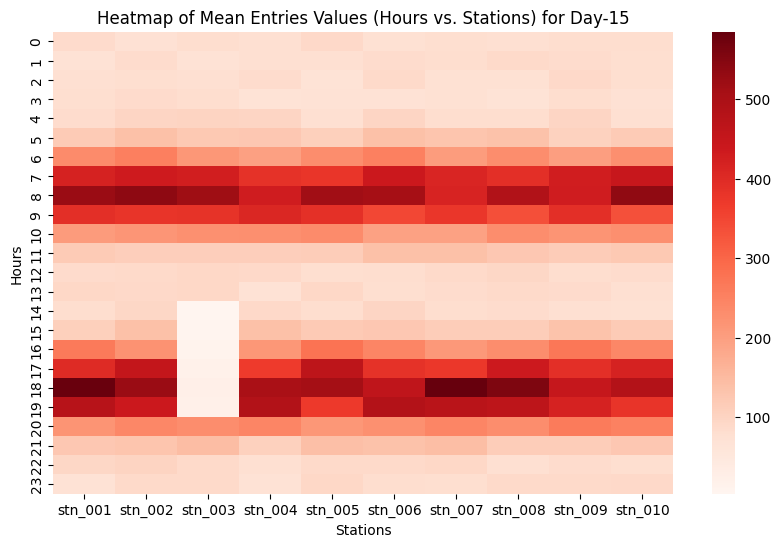

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_day_15_entries, cmap="Reds", cbar=True, yticklabels=1)

plt.title("Heatmap of Mean Entries Values (Hours vs. Stations) for Day-15")
plt.xlabel("Stations")
plt.ylabel("Hours")
plt.show()

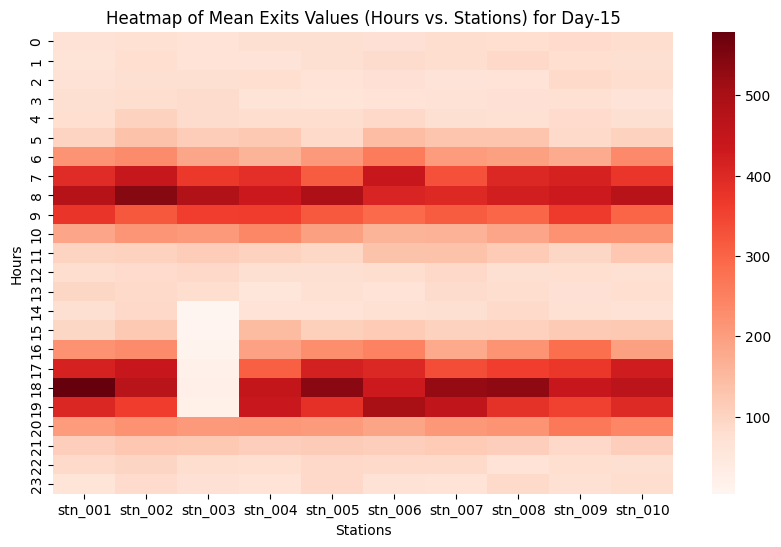

In [ ]:
plt.figure(figsize=(10, 6))
sns.heatmap(pivot_day_15_exits, cmap="Reds", cbar=True, yticklabels=1)

plt.title("Heatmap of Mean Exits Values (Hours vs. Stations) for Day-15")
plt.xlabel("Stations")
plt.ylabel("Hours")
plt.show()

### **Phase 4 — Multimodal Visualization ("The Reveal")**

**Panel 1 — Hourly subway entries for STN_003 (line or bar) — from Phase 3 pivot table.**

In [ ]:
stn_003_hour = pivot_day_15_entries[["stn_003"]].reset_index()
stn_003_hour.columns.name = None

**Panel 2 — Scooter rides per hour near STN_003 (bar) — count rides starting each hour on Day 15, from Phase 2 bounding-box subset.**

In [ ]:
stn_003_neighbours["hour"] = stn_003_neighbours["start_time"].dt.hour
stn_003_neighbours["day"] = stn_003_neighbours["start_time"].dt.day
stn_003_bounding_box = stn_003_neighbours.loc[stn_003_neighbours["day"]==15].reset_index()
stn_003_bounding_box.columns.name = None
stn_003_rides_per_hour = stn_003_bounding_box.groupby("hour")["ride_id"].count().reset_index()
stn_003_rides_per_hour.columns

Index(['hour', 'ride_id'], dtype='object')

**Panel 3 — Precipitation on Day 15 (line or bar) — from city_heartbeat.json.**

In [ ]:
city_heartbeat.columns = pd.to_datetime(city_heartbeat.columns, format="mixed")

day_15_col= city_heartbeat.loc["day_number"][city_heartbeat.loc["day_number"]==15].index[0]
precip_15 = city_heartbeat[day_15_col]["weather"]["precipitation_mm"]

prec_hours = np.arange(24)
precip_hourly = [precip_15] * 24

**3 Stacked Panels**

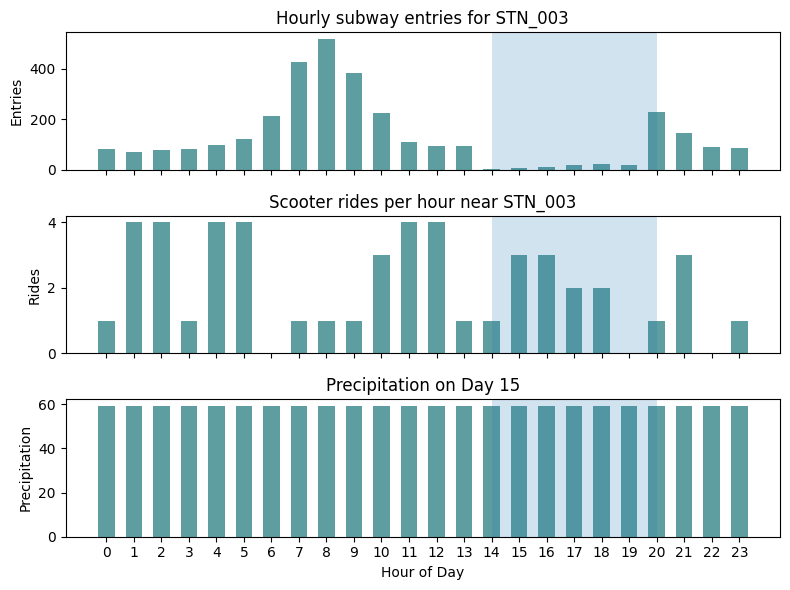

In [ ]:
fig, axes = plt.subplots(3, 1, sharex=True, figsize = (8, 6))

axes = axes.flatten()

axes[0].bar(stn_003_hour["hour"], stn_003_hour["stn_003"], width=0.6, color=["#5F9EA0"])
axes[0].set_title("Hourly subway entries for STN_003")
axes[0].set_ylabel("Entries")
axes[0].axvspan(14, 20, alpha=0.2)

axes[1].bar(stn_003_rides_per_hour["hour"], stn_003_rides_per_hour["ride_id"], width=0.6, color=["#5F9EA0"])
axes[1].set_title("Scooter rides per hour near STN_003")
axes[1].set_ylabel("Rides")
axes[1].axvspan(14, 20, alpha=0.2)

axes[2].bar(prec_hours, precip_hourly, width=0.6, color=["#5F9EA0"])
axes[2].set_title("Precipitation on Day 15")
axes[2].set_ylabel("Precipitation")
axes[2].set_xlabel("Hour of Day")
axes[2].set_xticks(range(24))
axes[2].axvspan(14, 20, alpha=0.2)

plt.tight_layout()
plt.show()